In [1]:
%load_ext nbproxy

Chave:  dxvw
Senha: ········



Variáveis de ambiente http_proxy e https_proxy configuradas!


## Boilerplate version

In [21]:
pathtst = '/tatu/dxvw/projetos/edge_corrosion/final_model/lightning/models/segformer-b4-finetuned-cityscapes-1024-1024'

In [24]:
pathtst.split('/')[-1]

'segformer-b4-finetuned-cityscapes-1024-1024'

In [54]:
from transformers import SegformerForSemanticSegmentation

class SegformerBoilerTest(nn.Module):
    def __init__(self, model_weights_path, id2label):
        super(SegformerBoilerTest, self).__init__()

        self.id2label = id2label
        self.num_classes = len(id2label.keys())
        self.label2id = {v:k for k,v in self.id2label.items()}

        self.model = SegformerForSemanticSegmentation.from_pretrained(
            model_weights_path,
            local_files_only=True, 
            return_dict=False, 
            num_labels=self.num_classes,
            id2label=self.id2label,
            label2id=self.label2id,
            ignore_mismatched_sizes=True,
        )

    def forward(self, images, masks):
        outputs = self.model(pixel_values=images, labels=masks)
        return(outputs)

In [59]:
chosen_weights_path = '/tatu/dxvw/projetos/edge_corrosion/final_model/lightning/models/segformer-b0-finetuned-cityscapes-1024-1024'
model = SegformerBoilerTest(model_weights_path=chosen_weights_path, id2label=train_dataset.id2label).to(device='cuda')

Some weights of SegformerForSemanticSegmentation were not initialized from the model checkpoint at /tatu/dxvw/projetos/edge_corrosion/final_model/lightning/models/segformer-b0-finetuned-cityscapes-1024-1024 and are newly initialized because the shapes did not match:
- decode_head.classifier.weight: found shape torch.Size([19, 256, 1, 1]) in the checkpoint and torch.Size([3, 256, 1, 1]) in the model instantiated
- decode_head.classifier.bias: found shape torch.Size([19]) in the checkpoint and torch.Size([3]) in the model instantiated
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


In [79]:
class meanIoU(torch.nn.Module):
    def __init__(self):
        super().__init__()
        self.mIoU = evaluate.load('mean_iou')

    def forward(self, predicted, masks, num_classes):

        self.mIoU.add_batch(
            predictions=predicted.detach().cpu().numpy(), 
            references=masks.detach().cpu().numpy()
        )
        metrics = self.mIoU.compute(
                num_labels=num_classes, 
                ignore_index=255, 
                reduce_labels=False,
            )
        
        return metrics

In [155]:
model.num_classes

3

In [154]:
metric = meanIoU()
loss_function = evaluate.load("mean_iou")

val_loss = torch.tensor(0.0).to(device='cuda')
metric_loss = torch.zeros(3 + 2*(model.num_classes)).to(device='cuda')

for batch, img_lbl_pair in enumerate(list(train_dataloader)):

    inputs = img_lbl_pair['pixel_values'].float().to(device='cuda')
    targets = img_lbl_pair['labels'].to(device='cuda')
    outputs = model(inputs, targets)
    loss, logits = outputs[0], outputs[1] # loss = self.batch_loss
    val_loss += loss
    
    upsampled_logits = nn.functional.interpolate(
            logits, 
            size=masks.shape[-2:], 
            mode="bilinear", 
            align_corners=False
        )

    predicted = upsampled_logits.argmax(dim=1)

    calculated_metrics = metric(predicted, targets, model.num_classes)

    metrics_list = []
    for _, value in calculated_metrics.items():
        if type(value)==np.ndarray:
            for element in value:
                metrics_list.append(element)
        else:
            metrics_list.append(value)
 
    metric_loss += torch.tensor(metrics_list).to(device='cuda')

# average loss and metrics
metric_loss /= len(val_dataloader)
val_loss /= len(val_dataloader)

[0.09706245644605482, 0.35000750835939337, 0.18182373046875, 0.09764895050193385, 0.06281758130081301, 0.13072083753541758, 0.10040438794432405, 0.14082301010963977, 0.8087951270242163]


tensor(1.1500, device='cuda:0', grad_fn=<NllLoss2DBackward0>)


tensor([0.0971, 0.3500, 0.1818, 0.0976, 0.0628, 0.1307, 0.1004, 0.1408, 0.8088],
       device='cuda:0')


tensor(1.1500, device='cuda:0', grad_fn=<AddBackward0>)



[0.10195919118059321, 0.3068144180479449, 0.184844970703125, 0.14217013844946721, 0.08958905503000712, 0.0741183800623053, 0.1454503081464602, 0.15951281354704339, 0.6154801324503312]


tensor(1.1990, device='cuda:0', grad_fn=<NllLoss2DBackward0>)


tensor([0.1990, 0.6568, 0.3667, 0.2398, 0.1524, 0.2048, 0.2459, 0.3003, 1.4243],
       device='cuda:0')


tensor(2.3490, device='cuda:0', grad_fn=<AddBackward0>)



[0.12478723126959118, 0.25483057096883555, 0.2245635986328125, 0.16790310024270733, 0.09579028109912918, 0.11066831246693705, 0.1818835726864598, 0.3063271048264916, 

## Lightning Version

In [29]:
from matplotlib import pyplot as plt

In [30]:
from torch.utils.data import Dataset, DataLoader
from PIL import Image
import os

class SemanticSegmentationDataset(Dataset):
    """Image (semantic) segmentation dataset."""

    def __init__(self, root_dir, feature_extractor):
        self.root_dir = root_dir
        self.feature_extractor = feature_extractor
        self.classes_csv_file = os.path.join(self.root_dir, "_classes.csv")
        with open(self.classes_csv_file, 'r') as fid:
            data = [l.split(',') for i,l in enumerate(fid) if i !=0]
        self.id2label = {x[0]:x[1] for x in data}
        
        image_file_names = [f for f in os.listdir(os.path.join(self.root_dir,'dataset')) if '.jpg' in f]
        mask_file_names = [f for f in os.listdir(os.path.join(self.root_dir,'dataset')) if '.png' in f]
        
        self.images = sorted(image_file_names)
        self.masks = sorted(mask_file_names)

    def __len__(self):
        return len(self.images)

    def __getitem__(self, idx):
        
        image = Image.open(os.path.join(self.root_dir, 'dataset', self.images[idx]))
        segmentation_map = Image.open(os.path.join(self.root_dir, 'dataset', self.masks[idx]))
        
        encoded_inputs = self.feature_extractor(image, segmentation_map, return_tensors="pt")

        for k,v in encoded_inputs.items():
          encoded_inputs[k].squeeze_()

        return encoded_inputs

In [31]:
from transformers import SegformerImageProcessor

processor = SegformerImageProcessor.from_pretrained('/tatu/dxvw/projetos/edge_corrosion/final_model/lightning/models/segformer-b0-finetuned-cityscapes-1024-1024', local_files_only=True)
# processor.do_reduce_labels = True
processor.size = 128

In [32]:
prepend_path = '/tatu/dxvw/projetos/edge_corrosion/final_model/lightning'

train_dataset = SemanticSegmentationDataset(prepend_path, processor)
val_dataset = SemanticSegmentationDataset(prepend_path, processor)
test_dataset = SemanticSegmentationDataset(prepend_path, processor)

batch_size = 4
train_dataloader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True, num_workers=3, prefetch_factor=8)
val_dataloader = DataLoader(val_dataset, batch_size=batch_size, num_workers=3, prefetch_factor=8)
test_dataloader = DataLoader(test_dataset, batch_size=batch_size, num_workers=3, prefetch_factor=8)

In [6]:
import pytorch_lightning as pl
from transformers import SegformerForSemanticSegmentation
import evaluate

import torch
from torch import nn

import numpy as np

class SegformerFinetuner(pl.LightningModule):
    
    def __init__(self, id2label, train_dataloader=None, val_dataloader=None, test_dataloader=None, metrics_interval=100):
        super(SegformerFinetuner, self).__init__()
        self.id2label = id2label
        self.metrics_interval = metrics_interval
        self.train_dl = train_dataloader
        self.val_dl = val_dataloader
        self.test_dl = test_dataloader

        self.validation_step_outputs = []
        self.train_step_outputs = []
        
        self.num_classes = len(id2label.keys())
        self.label2id = {v:k for k,v in self.id2label.items()}
        
        self.model = SegformerForSemanticSegmentation.from_pretrained(
            '/tatu/dxvw/projetos/edge_corrosion/final_model/lightning/models/segformer-b4-finetuned-cityscapes-1024-1024', 
            local_files_only=True,  
            return_dict=False, 
            num_labels=self.num_classes,
            id2label=self.id2label,
            label2id=self.label2id,
            ignore_mismatched_sizes=True,
        )
        
        self.train_mean_iou = evaluate.load("mean_iou")
        self.val_mean_iou = evaluate.load("mean_iou")
        self.test_mean_iou = evaluate.load("mean_iou")
        
    def forward(self, images, masks):
        outputs = self.model(pixel_values=images, labels=masks)
        return(outputs)
    
    def training_step(self, batch, batch_nb):
        
        images, masks = batch['pixel_values'], batch['labels']
        
        outputs = self(images, masks)
        
        loss, logits = outputs[0], outputs[1]
        
        upsampled_logits = nn.functional.interpolate(
            logits, 
            size=masks.shape[-2:], 
            mode="bilinear", 
            align_corners=False
        )

        predicted = upsampled_logits.argmax(dim=1)

        self.train_mean_iou.add_batch(
            predictions=predicted.detach().cpu().numpy(), 
            references=masks.detach().cpu().numpy()
        )
        if batch_nb % self.metrics_interval == 0:

            metrics = self.train_mean_iou.compute(
                num_labels=self.num_classes, 
                ignore_index=255, 
                reduce_labels=False,
            )
            
            metrics = {'loss': loss, "mean_iou": metrics["mean_iou"], "mean_accuracy": metrics["mean_accuracy"]}
            
            for k,v in metrics.items():
                self.log(k,v)
            
            return(metrics)
        else:
            return({'loss': loss})
    
    def validation_step(self, batch, batch_nb):
        
        images, masks = batch['pixel_values'], batch['labels']
        
        outputs = self(images, masks)
        
        loss, logits = outputs[0], outputs[1]
        self.validation_step_outputs.append(loss)
        
        upsampled_logits = nn.functional.interpolate(
            logits, 
            size=masks.shape[-2:], 
            mode="bilinear", 
            align_corners=False
        )
        
        predicted = upsampled_logits.argmax(dim=1)
        
        self.val_mean_iou.add_batch(
            predictions=predicted.detach().cpu().numpy(), 
            references=masks.detach().cpu().numpy()
        )
        
        return({'val_loss': loss})
    
    def on_validation_epoch_end(self):
        metrics = self.val_mean_iou.compute(
              num_labels=self.num_classes, 
              ignore_index=255, 
              reduce_labels=False,
          )
        
        avg_val_loss = torch.stack(self.validation_step_outputs).mean()
        val_mean_iou = metrics["mean_iou"]
        val_mean_accuracy = metrics["mean_accuracy"]
        
        metrics = {"val_loss": avg_val_loss, "val_mean_iou":val_mean_iou, "val_mean_accuracy":val_mean_accuracy}
        for k,v in metrics.items():
            self.log(k,v)
        self.validation_step_outputs.clear()
        
        return metrics
    
    def test_step(self, batch, batch_nb):
        
        images, masks = batch['pixel_values'], batch['labels']
        
        outputs = self(images, masks)
        
        loss, logits = outputs[0], outputs[1]
        self.train_step_outputs.append(loss)
        
        upsampled_logits = nn.functional.interpolate(
            logits, 
            size=masks.shape[-2:], 
            mode="bilinear", 
            align_corners=False
        )
        
        predicted = upsampled_logits.argmax(dim=1)
        
        self.test_mean_iou.add_batch(
            predictions=predicted.detach().cpu().numpy(), 
            references=masks.detach().cpu().numpy()
        )
            
        return({'test_loss': loss})
    
    def on_test_epoch_end(self):
        metrics = self.test_mean_iou.compute(
              num_labels=self.num_classes, 
              ignore_index=255, 
              reduce_labels=False,
          )
       
        avg_test_loss = torch.stack(self.train_step_outputs).mean()
        test_mean_iou = metrics["mean_iou"]
        test_mean_accuracy = metrics["mean_accuracy"]

        metrics = {"test_loss": avg_test_loss, "test_mean_iou":test_mean_iou, "test_mean_accuracy":test_mean_accuracy}
        
        for k,v in metrics.items():
            self.log(k,v)
        self.train_step_outputs.clear()
        
        return metrics
    
    def configure_optimizers(self):
        return torch.optim.Adam([p for p in self.parameters() if p.requires_grad], lr=2e-05, eps=1e-08)
    
    def train_dataloader(self):
        return self.train_dl
    
    def val_dataloader(self):
        return self.val_dl
    
    def test_dataloader(self):
        return self.test_dl

In [7]:
segformer_finetuner = SegformerFinetuner(
    train_dataset.id2label, 
    train_dataloader=train_dataloader, 
    val_dataloader=val_dataloader, 
    test_dataloader=test_dataloader, 
    metrics_interval=10,
)

config.json:   0%|          | 0.00/1.68k [00:00<?, ?B/s]

pytorch_model.bin:   0%|          | 0.00/256M [00:00<?, ?B/s]

Some weights of SegformerForSemanticSegmentation were not initialized from the model checkpoint at nvidia/segformer-b4-finetuned-cityscapes-1024-1024 and are newly initialized because the shapes did not match:
- decode_head.classifier.weight: found shape torch.Size([19, 768, 1, 1]) in the checkpoint and torch.Size([3, 768, 1, 1]) in the model instantiated
- decode_head.classifier.bias: found shape torch.Size([19]) in the checkpoint and torch.Size([3]) in the model instantiated
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


model.safetensors:   0%|          | 0.00/256M [00:00<?, ?B/s]

In [8]:
from pytorch_lightning.callbacks.early_stopping import EarlyStopping
from pytorch_lightning.callbacks.model_checkpoint import ModelCheckpoint

early_stop_callback = EarlyStopping(
    monitor="val_loss", 
    min_delta=0.00, 
    patience=30, 
    verbose=False, 
    mode="min",
)

checkpoint_callback = ModelCheckpoint(save_top_k=1, monitor="val_loss")

trainer = pl.Trainer(
    accelerator="auto", 
    callbacks=[early_stop_callback, checkpoint_callback],
    max_epochs=500,
    val_check_interval=len(train_dataloader),
)

GPU available: True (cuda), used: True
TPU available: False, using: 0 TPU cores
HPU available: False, using: 0 HPUs


In [9]:
trainer.fit(segformer_finetuner)

/u/dxvw/.local/lib/python3.10/site-packages/pytorch_lightning/callbacks/model_checkpoint.py:654: Checkpoint directory /tatu/dxvw/projetos/edge_corrosion/final_model/lightning/lightning_logs/version_77955/checkpoints exists and is not empty.
LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]

  | Name  | Type                             | Params | Mode
------------------------------------------------------------------
0 | model | SegformerForSemanticSegmentation | 64.0 M | eval
------------------------------------------------------------------
64.0 M    Trainable params
0         Non-trainable params
64.0 M    Total params
255.981   Total estimated model params size (MB)
0         Modules in train mode
937       Modules in eval mode
SLURM auto-requeueing enabled. Setting signal handlers.


Sanity Checking: |          | 0/? [00:00<?, ?it/s]

/u/dxvw/.local/lib/python3.10/site-packages/datasets/features/image.py:348: UserWarning: Downcasting array dtype int64 to int32 to be compatible with 'Pillow'
  warnings.warn(f"Downcasting array dtype {dtype} to {dest_dtype} to be compatible with 'Pillow'")
/u/dxvw/.local/lib/python3.10/site-packages/pytorch_lightning/loops/fit_loop.py:310: The number of training batches (3) is smaller than the logging interval Trainer(log_every_n_steps=50). Set a lower value for log_every_n_steps if you want to see logs for the training epoch.


Training: |          | 0/? [00:00<?, ?it/s]

Validation: |          | 0/? [00:00<?, ?it/s]

...

Validation: |          | 0/? [00:00<?, ?it/s]

Validation: |          | 0/? [00:00<?, ?it/s]

Validation: |          | 0/? [00:00<?, ?it/s]

Validation: |          | 0/? [00:00<?, ?it/s]

`Trainer.fit` stopped: `max_epochs=500` reached.


In [10]:
res = trainer.test(ckpt_path="best")

Restoring states from the checkpoint path at /tatu/dxvw/projetos/edge_corrosion/final_model/lightning/lightning_logs/version_77955/checkpoints/epoch=487-step=1464.ckpt
LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]
Loaded model weights from the checkpoint at /tatu/dxvw/projetos/edge_corrosion/final_model/lightning/lightning_logs/version_77955/checkpoints/epoch=487-step=1464.ckpt
SLURM auto-requeueing enabled. Setting signal handlers.


Testing: |          | 0/? [00:00<?, ?it/s]

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━┓
┃        Test metric        ┃       DataLoader 0        ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━┩
│         test_loss         │    0.11216212809085846    │
│    test_mean_accuracy     │    0.9387345314025879     │
│       test_mean_iou       │     0.890911340713501     │
└───────────────────────────┴───────────────────────────┘

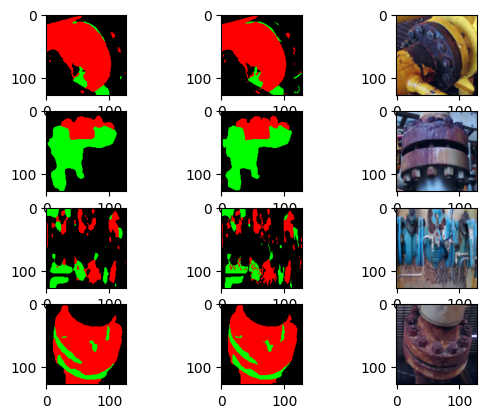

In [11]:
color_map = {
    1:(255,0,0),
    2:(0,255,0)
}

def prediction_to_vis(prediction):
    vis_shape = prediction.shape + (3,)
    vis = np.zeros(vis_shape)
    for i,c in color_map.items():
        vis[prediction == i] = color_map[i]
    return Image.fromarray(vis.astype(np.uint8))

def norm_img(tensor:torch.tensor):
    img = tensor.permute(1,2,0).detach().cpu().numpy()
    nimg = (img - np.min(img)) / (np.max(img) - np.min(img)) * 255
    return nimg.astype(np.uint8)

for batch in test_dataloader:
    images, masks = batch['pixel_values'], batch['labels']
    outputs = segformer_finetuner.model(images, masks)
        
    loss, logits = outputs[0], outputs[1]

    upsampled_logits = nn.functional.interpolate(
        logits, 
        size=masks.shape[-2:], 
        mode="bilinear", 
        align_corners=False
    )

    predicted = upsampled_logits.argmax(dim=1).cpu().numpy()
    masks = masks.cpu().numpy()
    break

f, axarr = plt.subplots(predicted.shape[0],3)
for i in range(predicted.shape[0]):
    
    axarr[i,0].imshow(prediction_to_vis(predicted[i,:,:]))
    axarr[i,1].imshow(prediction_to_vis(masks[i,:,:]))
    axarr[i,2].imshow(norm_img(images[i]))

## Misc

In [ ]:
ii = images[i].permute(1,2,0).detach().cpu().numpy()

In [ ]:
ii.min(), ii.max()

In [ ]:
normalized_array = (array - np.min(array)) / (np.max(array) - np.min(array))

In [ ]:
nii = norm_img(images[i])

In [ ]:
plt.imshow(nii)

In [ ]:
plt.imshow(predicted[0])

In [ ]:
np.unique(predicted[0])

In [ ]:
ue = np.asarray(val_dataset[1]['labels'])

In [ ]:
plt.imshow(ue, cmap='tab20b')

In [ ]:
np.unique(ue)

In [ ]:
type(ue[0,0])

In [ ]:
import sys
np.set_printoptions(threshold=sys.maxsize)
plt.imshow(ue[0:50,0:50], cmap='tab20')

In [ ]:
ue[0:50,0:50]

In [ ]:
segformer_finetuner.id2label

In [ ]:
a = plt.imread('/tatu/dxvw/projetos/edge_corrosion/final_model/lightning/dataset/00432_3_semantic.png')

In [ ]:
plt.imshow(a, cmap='tab20b')

In [ ]:
np.unique(np.asarray(Image.open('/tatu/dxvw/projetos/edge_corrosion/final_model/lightning/dataset/00432_3_semantic.png')))

In [ ]:
Image.open('/tatu/dxvw/projetos/edge_corrosion/final_model/lightning/dataset/00432_3.jpg')